# 07. Explaining the tuned model with SHAP

A good AUC says the model works, not *why*. SHAP gives each feature a contribution to each individual prediction.
- **Bar plot:** average size of a feature's contribution, i.e. overall importance.
- **Beeswarm:** each dot is one applicant. Position = push towards default (right) or towards repaying (left); colour = the feature's value (red high, blue low). This shows the *direction* of the effect.

Steps: train the tuned model on 80% of applicants, check AUC on the other 20%, explain 10,000 of the held-out applicants.

In [1]:
# Rebuild the feature table, train the tuned model on 80% and check AUC on the 20% hold-out
import sys, json
# make the project's src/ package importable from the notebooks folder
sys.path.append("..")

import numpy as np
import pandas as pd
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

# project helpers for cleaning and feature engineering
from src.features import clean, add_features

df = pd.read_csv("../data/raw/HC_application_train.csv")
y = df["TARGET"]
# same feature table as in notebook 06
X = add_features(clean(df.drop(columns="TARGET")))
# attach the pre-computed aggregate tables
for name in ["bureau", "previous", "installments"]:
    X = X.join(pd.read_pickle(f"../data/processed/{name}.pkl"), on="SK_ID_CURR")
X = X.drop(columns="SK_ID_CURR")
# text columns become LightGBM native categories
for c in X.select_dtypes(include=["object", "string"]):
    X[c] = X[c].astype("category")

# stratified split keeps the 8% default rate in both parts
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# tuned settings saved by notebook 06
params = json.load(open("../models/best_params.json"))
# fit on the training part only
model = lgb.LGBMClassifier(**params, random_state=42, verbose=-1).fit(X_tr, y_tr)
print("hold-out AUC:", round(roc_auc_score(y_va, model.predict_proba(X_va)[:, 1]), 4))

hold-out AUC: 0.7918


**Insight:** hold-out AUC is 0.7918, in line with the 0.7914 five-fold mean from notebook 06 (the difference is well within the 0.003 to 0.004 noise), so this single model is a fair stand-in for the tuned one.

## Compute SHAP values
SHAP is slow on 518 features, so we explain a random sample of 10,000 held-out applicants. Each value says how much one feature pushed one applicant's score up (towards default) or down.

In [2]:
# Compute SHAP values for a random sample of 10,000 hold-out applicants
# sample from the hold-out so the explanations are on unseen applicants
sample = X_va.sample(10_000, random_state=42)
# exact and fast SHAP algorithm for tree models
sv = shap.TreeExplainer(model).shap_values(sample)
sv = sv[1] if isinstance(sv, list) else sv            # some versions return one array per class
print(sv.shape)

(10000, 518)


/Users/dhanyarajendran/Desktop/NeueFische/myproject/Home-Credit-Default-Risk/.venv/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


**Insight:** the result is a 10,000 by 518 matrix, one contribution per applicant and feature. The UserWarning is about a change in the library's output format; the next line handles both formats.

## Overall importance

The bar plot shows the average absolute SHAP value of the top 20 features and is also saved to `assets/shap_bar.png`.

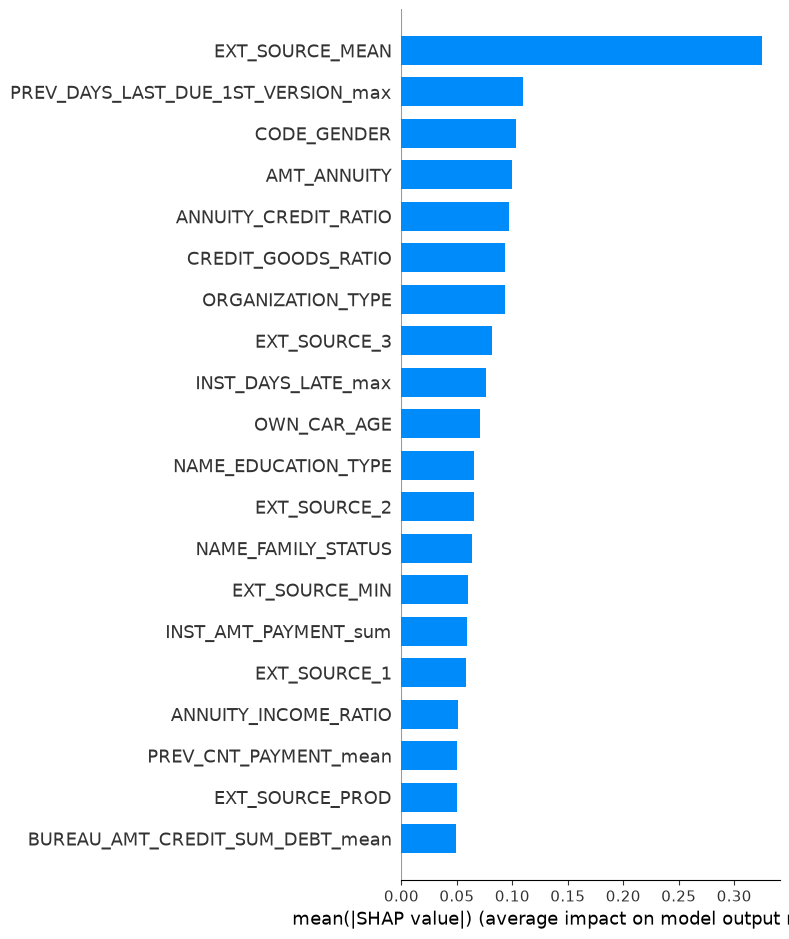

In [3]:
# Bar plot of overall feature importance (mean absolute SHAP value)
# make sure the output folder exists
Path("../assets").mkdir(exist_ok=True)
# show=False so we can save the figure before displaying it
shap.summary_plot(sv, sample, plot_type="bar", max_display=20, show=False)
plt.tight_layout(); plt.savefig("../assets/shap_bar.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight:** `EXT_SOURCE_MEAN` dominates at about 0.33, roughly three times the next feature (`PREV_DAYS_LAST_DUE_1ST_VERSION_max`, about 0.11). After that the importances fall off gradually, with no other single feature standing out.

## Direction of the effect

The beeswarm plot is also saved to `assets/shap_beeswarm.png`. Grey dots are categorical features, which have no low/high colour.

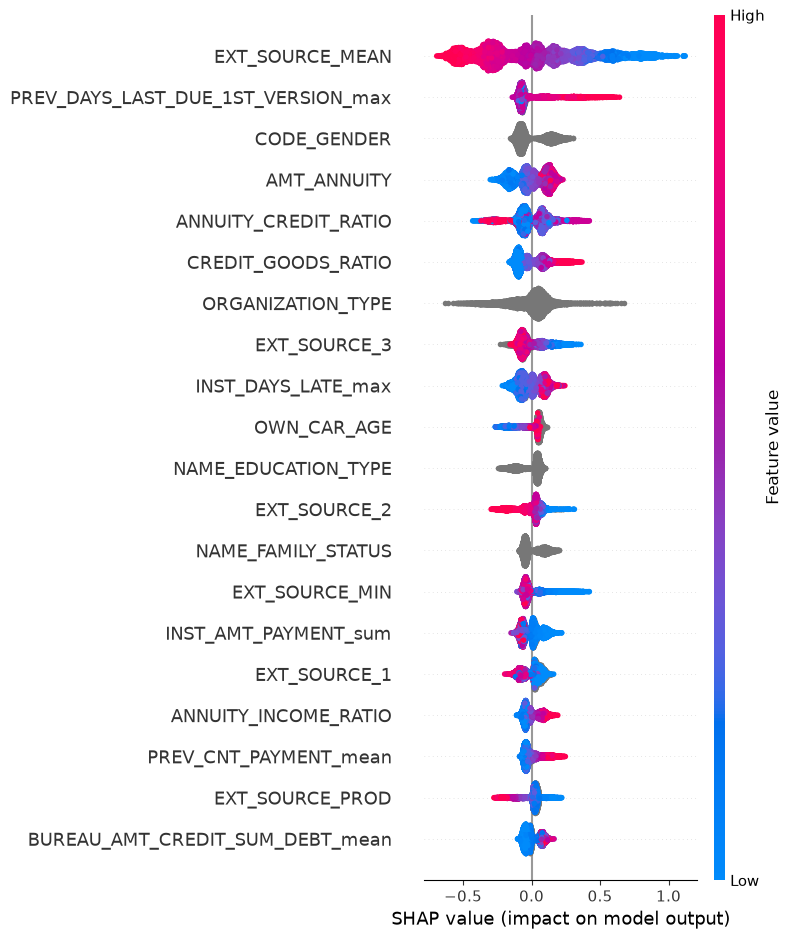

In [4]:
# Beeswarm plot: direction and spread of each feature's effect
# one dot per applicant; colour = feature value, x position = push on the score
shap.summary_plot(sv, sample, max_display=20, show=False)
plt.tight_layout(); plt.savefig("../assets/shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight:** low values of `EXT_SOURCE_MEAN`, `EXT_SOURCE_1`, `EXT_SOURCE_2` and `EXT_SOURCE_3` (blue) push the score towards default, high values (red) towards repaying. Higher `AMT_ANNUITY`, `CREDIT_GOODS_RATIO` and `PREV_DAYS_LAST_DUE_1ST_VERSION_max` push towards default. These directions fit the EDA, so there is no sign of leakage in the top features.

## Which table does the signal come from?
Add up the average absolute SHAP value of every feature, grouped by where the feature came from.

This is a rough guide to where the information comes from, not a measure of how much each table adds on its own, because the features are correlated.

In [5]:
# Group features by source table and sum their mean absolute SHAP values
# average impact of each feature over the 10,000 applicants
imp = pd.Series(np.abs(sv).mean(axis=0), index=sample.columns)
# map a column to its table using the name prefix set when the tables were built
def source(col):
    for prefix, label in [("BUREAU_", "bureau"), ("PREV_", "previous application"), ("INST_", "installments")]:
        if col.startswith(prefix): return label
    return "application"
# total importance and number of features per table
by_source = imp.groupby(imp.index.map(source)).agg(["sum", "count"])
# fraction of the total importance
by_source["share of total"] = (by_source["sum"] / by_source["sum"].sum()).round(3)
by_source.sort_values("sum", ascending=False).round(4)

,sum,count,share of total
application,2.1519,133,0.476
previous application,1.1348,224,0.251
bureau,0.6181,124,0.137
installments,0.6122,37,0.136


**Insight:** the application table gives 47.6% of the total importance, previous applications 25.1%, bureau 13.7% and installments 13.6%. Installments reach their share with only 37 features, while previous applications (224) and bureau (124) need many more, so the aggregates add signal but spread thinly.

The same importances at the level of single features, top 15.

In [6]:
# List the 15 individual features with the largest mean absolute SHAP value
imp.sort_values(ascending=False).head(15).round(4)

EXT_SOURCE_MEAN                       0.3250
PREV_DAYS_LAST_DUE_1ST_VERSION_max    0.1097
CODE_GENDER                           0.1037
AMT_ANNUITY                           0.0999
ANNUITY_CREDIT_RATIO                  0.0967
CREDIT_GOODS_RATIO                    0.0937
ORGANIZATION_TYPE                     0.0933
EXT_SOURCE_3                          0.0814
INST_DAYS_LATE_max                    0.0766
OWN_CAR_AGE                           0.0713
NAME_EDUCATION_TYPE                   0.0657
EXT_SOURCE_2                          0.0651
NAME_FAMILY_STATUS                    0.0640
EXT_SOURCE_MIN                        0.0604
INST_AMT_PAYMENT_sum                  0.0587
dtype: float64

**Insight:** `EXT_SOURCE_MEAN` (0.3250) leads and the remaining top 15 lie between 0.0587 and 0.1097. Several engineered features (`ANNUITY_CREDIT_RATIO`, `CREDIT_GOODS_RATIO`, `EXT_SOURCE_MIN`) are in the list, and `CODE_GENDER` (0.1037) is a sensitive attribute that would need review before real use.

## Reading the result (fill in from the plots above)
Check each top feature against the EDA: does the direction make business sense (low external score -> higher default risk; late instalments -> higher risk)? A top feature that makes no business sense is a leakage warning.